In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("spscientist/students-performance-in-exams")

print(f"Path to dataset files:{path}/StudentsPerformance.csv")

100%|██████████| 8.70k/8.70k [00:00<00:00, 14.4MB/s]

Extracting files...
Path to dataset files:/root/.cache/kagglehub/datasets/spscientist/students-performance-in-exams/versions/1/StudentsPerformance.csv


In [4]:
df = pd.read_table("/root/.cache/kagglehub/datasets/spscientist/students-performance-in-exams/versions/1/StudentsPerformance.csv",sep=",")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [7]:
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [6]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
num_col = df.select_dtypes(include=['int64','float64']).columns
cat_col = df.select_dtypes(include=['object']).columns

In [9]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()
df[cat_col] = oe.fit_transform(df[cat_col])

In [11]:
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,0.0,1.0,1.0,1.0,1.0,72,72,74
1,0.0,2.0,4.0,1.0,0.0,69,90,88
2,0.0,1.0,3.0,1.0,1.0,90,95,93
3,1.0,0.0,0.0,0.0,1.0,47,57,44
4,1.0,2.0,4.0,1.0,1.0,76,78,75


In [12]:
df.describe()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,0.482000,2.174000,2.486000,0.645000,0.642000,66.08900,69.169000,68.054000
std,0.499926,1.157179,1.829522,0.478753,0.479652,15.16308,14.600192,15.195657
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,17.000000,10.000000
25%,0.000000,1.000000,1.000000,0.000000,0.000000,57.00000,59.000000,57.750000
50%,0.000000,2.000000,2.000000,1.000000,1.000000,66.00000,70.000000,69.000000
75%,1.000000,3.000000,4.000000,1.000000,1.000000,77.00000,79.000000,79.000000
max,1.000000,4.000000,5.000000,1.000000,1.000000,100.00000,100.000000,100.000000


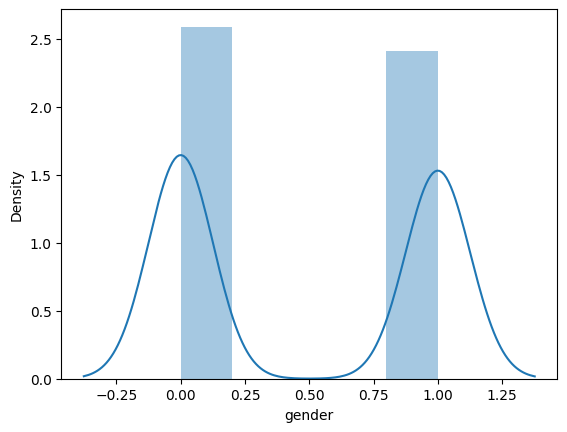

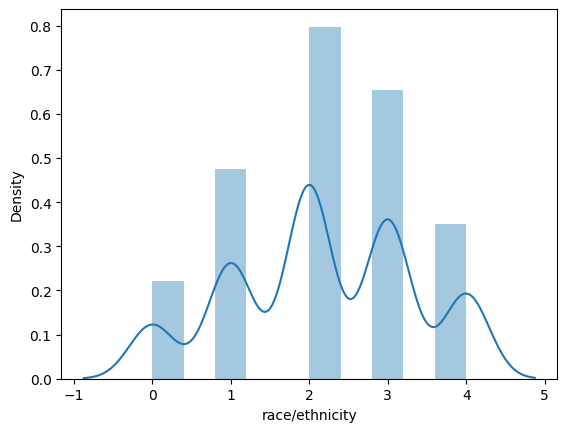

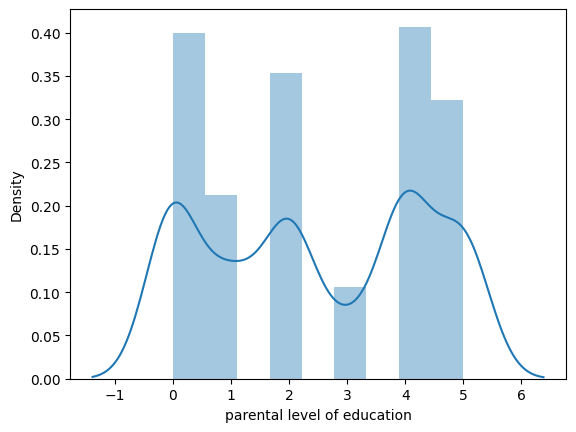

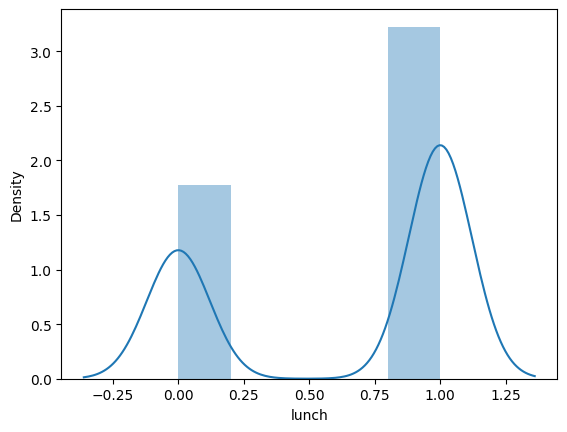

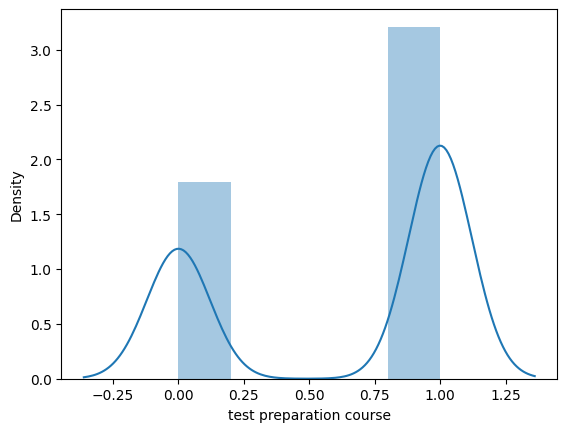

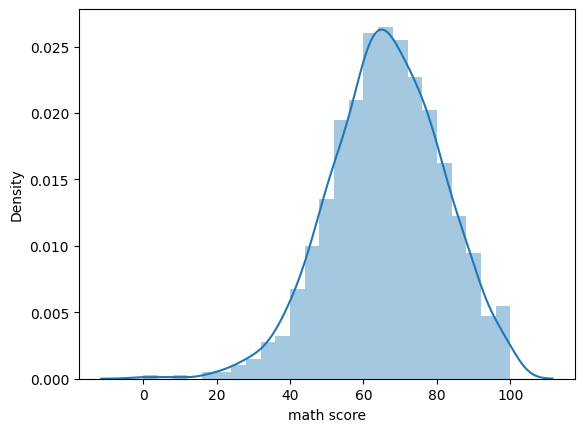

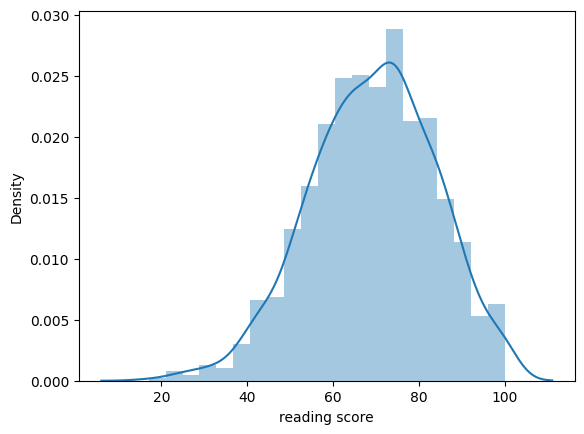

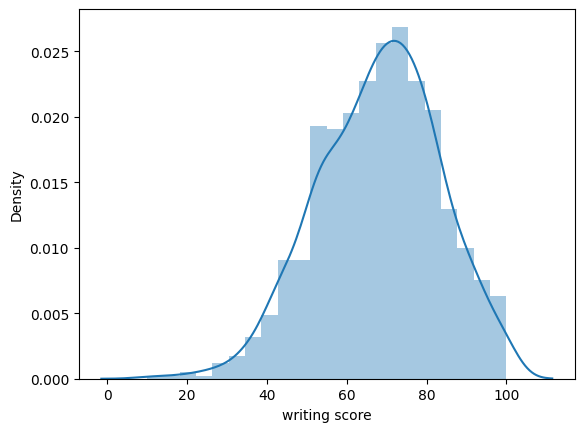

In [19]:
for i in df.columns:
  sns.distplot(df[i])
  plt.show()

In [21]:
%pip install -q outlier-tool-shashikant

In [22]:
from outlier_tool import Outliers
o = Outliers(df)

In [23]:
o.find("iqr")

,column,method,lower,upper,outliers,percent
0,gender,iqr,-1.500,2.500,0,0.0
1,race/ethnicity,iqr,-2.000,6.000,0,0.0
2,parental level of education,iqr,-3.500,8.500,0,0.0
3,lunch,iqr,-1.500,2.500,0,0.0
4,test preparation course,iqr,-1.500,2.500,0,0.0
5,math score,iqr,27.000,107.000,8,0.8
6,reading score,iqr,29.000,109.000,6,0.6
7,writing score,iqr,25.875,110.875,5,0.5


In [25]:
X = df.drop('math score', axis=1)
Y = df['math score']

In [26]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [30]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

RFR = RandomForestRegressor()
RFR.fit(X_train, Y_train)
ypred = RFR.predict(X_test)

r2 = r2_score(Y_test, ypred)
print("R-squared:", r2)

train = RFR.score(X_train, Y_train)
print("Train Score:", train)

test = RFR.score(X_test, Y_test)
print("Test Score:", test)

R-squared: 0.8490284928884586
Train Score: 0.9765200334042105
Test Score: 0.8490284928884586


In [32]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

L2 = Ridge(alpha=10)
L2.fit(X_train,Y_train)
y_pred = L2.predict(X_test)

r2= r2_score(Y_test,y_pred)
print(f"R2 score is {r2}")

train= L2.score(X_train,Y_train)
print(f"train score is {train}")

test= L2.score(X_test,Y_test)
print(f"test score is {test}")

R2 score is 0.8824940139800163
train score is 0.8609632029456191
test score is 0.8824940139800163


In [35]:
new = {}

# We will prompt for the original values and transform categorical columns dynamically
for col in X.columns:
    value = input(f"Enter {col}: ")

    if col in cat_col:
        # Find the index of this column in the encoder's categories
        col_idx = list(cat_col).index(col)
        # Use the encoder's categories to map the input string to its encoded float representation
        categories_list = list(oe.categories_[col_idx])
        if value in categories_list:
            encoded_value = float(categories_list.index(value))
        else:
            # Handle potential case-sensitivity or leading/trailing spaces
            cleaned_value = value.strip()
            if cleaned_value in categories_list:
                encoded_value = float(categories_list.index(cleaned_value))
            else:
                print(f"Warning: '{value}' not recognized. Available options: {categories_list}")
                encoded_value = 0.0
        new[col] = [encoded_value]
    else:
        new[col] = [float(value)]

new_df = pd.DataFrame(new)

# Make prediction using the trained Ridge model (L2)
predicted_math_score = L2.predict(new_df)[0]

print(f"\n\t Predicted math score: {predicted_math_score:.4f}")

Enter gender: male
Enter race/ethnicity: group A
Enter parental level of education: some college	
Enter lunch: free/reduced
Enter test preparation course: none
Enter reading score: 14
Enter writing score: 45

	 Predicted math score: 36.7938
